# Predict new — Fruits CNN

This notebook adapts the reference `Predict.ipynb` for the four-class fruit CNN.

It loads the trained model and predicts one new image at a time.

**Output classes:** Apple, Banana, Mango, Orange  
**Expected model:** `models/fruit_cnn_model.keras`  
**Input image size:** 128 × 128 RGB, normalized to [0, 1].

Put new photographs in a `predict/` folder, or update `IMAGE_PATH` below.

In [8]:
from pathlib import Path
import tensorflow as tf

PROJECT_DIR = Path.cwd()
MODEL_PATH = PROJECT_DIR / "models/fruit_cnn_model.keras"
PREDICT_DIR = PROJECT_DIR / "predict"

CLASS_NAMES = ["apple", "banana", "mango", "orange"]
IMAGE_SIZE = (128, 128)

PREDICT_DIR.mkdir(exist_ok=True)

if not MODEL_PATH.exists():
    raise FileNotFoundError(f"Model not found: {MODEL_PATH}. Train the model first.")

model = tf.keras.models.load_model(MODEL_PATH)

print("Model loaded:", MODEL_PATH)
print("Prediction folder:", PREDICT_DIR)

Model loaded: C:\Users\fhv\rahat-codes\Multilevel Classification CNN Model Project\models\fruit_cnn_model.keras
Prediction folder: C:\Users\fhv\rahat-codes\Multilevel Classification CNN Model Project\predict


## 1. Define the prediction function

The reference uses OpenCV BGR images. Here we use Pillow RGB consistently with Keras directory loading. The image is resized to 128×128 and normalized exactly as in training.

In [9]:
def predict_image(image_path):
    with Image.open(image_path) as img:
        original = img.convert("RGB").resize(IMAGE_SIZE)

    batch = np.expand_dims(np.asarray(original) / 255.0, axis=0)
    probs = model.predict(batch, verbose=0)[0]

    index = np.argmax(probs)
    predicted_class = CLASS_NAMES[index]
    confidence = probs[index]

    print(f"Prediction: {predicted_class.title()} ({confidence:.2%})")
    for name, prob in zip(CLASS_NAMES, probs):
        print(f"{name.title():10}: {prob:.2%}")

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].imshow(original)
    ax[0].set_title(f"{predicted_class.title()} ({confidence:.2%})")
    ax[0].axis("off")

    ax[1].bar(CLASS_NAMES, probs)
    ax[1].set(ylim=(0, 1), ylabel="Probability", title="Class Probabilities")
    ax[1].tick_params(axis="x", rotation=30)

    plt.tight_layout()
    plt.show()

    return {
        "class": predicted_class,
        "confidence": float(confidence),
        "probabilities": dict(zip(CLASS_NAMES, probs.tolist()))
    }

## 2. Predict a new fruit image

Copy a photograph into the `predict/` folder, then change the filename below. Supported formats include JPG, JPEG, PNG, BMP, and WEBP.

In [19]:
images = list(PREDICT_DIR.glob("*"))
print([img.name for img in images if img.suffix.lower() in [".jpg", ".jpeg", ".png"]])

['apple_68.jpg', 'Banana(lady_finger)_3.jpg', 'mango_2.jpg', 'orange2.jpg']


Prediction: Orange (87.20%)
Apple     : 1.47%
Banana    : 5.06%
Mango     : 6.26%
Orange    : 87.20%


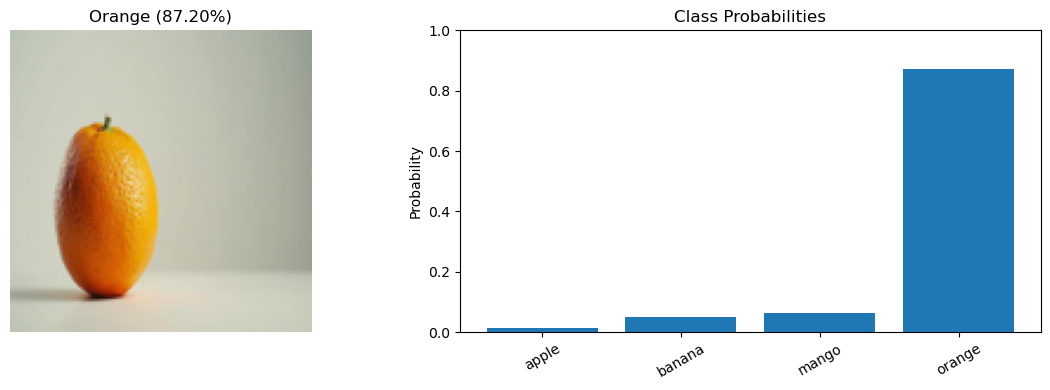

In [14]:
IMAGE_PATH = PREDICT_DIR / "orange2.jpg"
result = predict_image(IMAGE_PATH)

Prediction: Banana (97.58%)
Apple     : 0.12%
Banana    : 97.58%
Mango     : 1.46%
Orange    : 0.85%


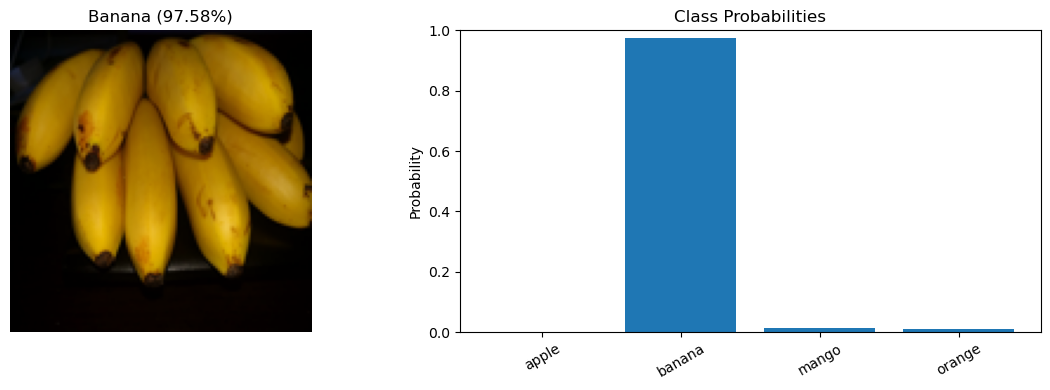

In [16]:
IMAGE_PATH = PREDICT_DIR / "Banana(lady_finger)_3.jpg"
result = predict_image(IMAGE_PATH)

Prediction: Orange (92.46%)
Apple     : 0.59%
Banana    : 3.18%
Mango     : 3.77%
Orange    : 92.46%


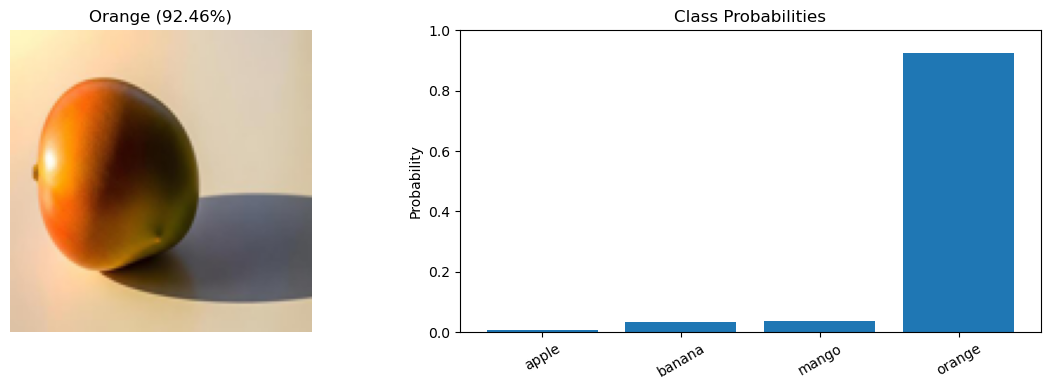

In [18]:
IMAGE_PATH = PREDICT_DIR / "mango_2.jpg"
result = predict_image(IMAGE_PATH)

Prediction: Apple (97.84%)
Apple     : 97.84%
Banana    : 1.97%
Mango     : 0.15%
Orange    : 0.04%


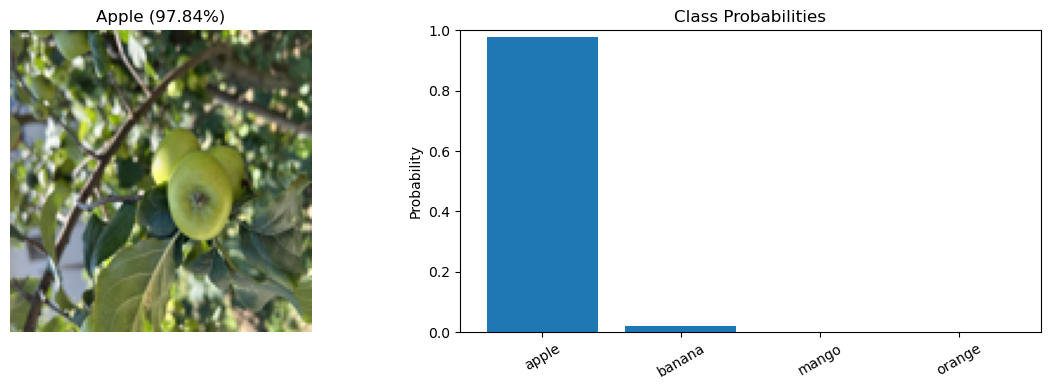

In [20]:
IMAGE_PATH = PREDICT_DIR / "apple_68.jpg"
result = predict_image(IMAGE_PATH)

## 3. Optional: list available prediction images

Found 6 image(s) in C:\Users\fhv\rahat-codes\Multilevel Classification CNN Model Project\predict:
- apple_68.jpg
- Banana(lady_finger)_3.jpg
- mango.webp
- mango_2.jpg
- orange2.jpg
- orange_Test.webp
Prediction: Orange (100.00%)
Apple     : 0.00%
Banana    : 0.00%
Mango     : 0.00%
Orange    : 100.00%


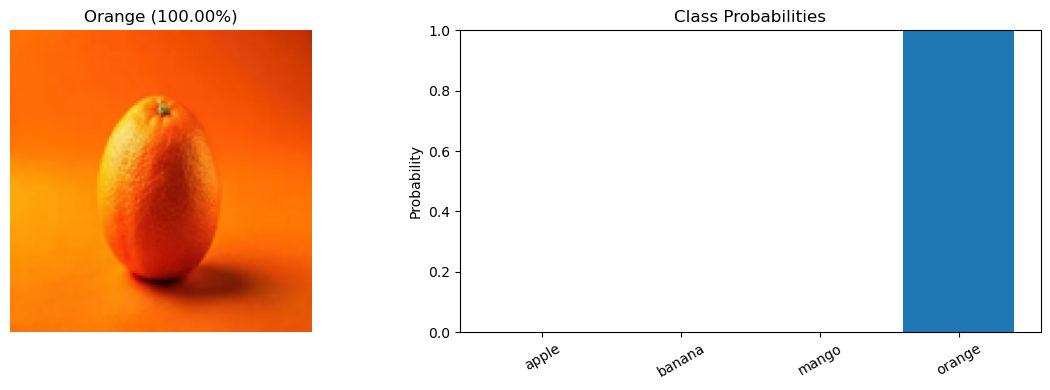

In [30]:
SUPPORTED_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

available_images = sorted(
    p for p in PREDICT_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in SUPPORTED_EXTENSIONS
)

print(f"Found {len(available_images)} image(s) in {PREDICT_DIR}:")
for image_path in available_images:
    print("-", image_path.name)

# Predict the first available image, if one exists.
if available_images:
    result = predict_image(available_images[-1])
else:
    print("Add a fruit photograph to the predict folder, then rerun this cell.")